# Information of imaginary dataset

There're 3 columns, `Yearly Salary`, `Height` and `Maritial Status`
Using these 3 columns, we have to predict the `Age (Regression problem)` and `City (Delhi/Mumbai) (Classification problem)`

So, let's create a small non-linear architecture of neural network for this problem

In [1]:
from keras.models import Model

In [9]:
model = Model(inputs = x, outputs = [output1, output2])

# We will not pass values to inputs and outputs parameter as for now, will pass it later 

# We pass two arguments to Model i.e inputs and outputs
# inputs: Takes which layer is input layer and there can me multiple input layers
# outputs: Takes output layers and there can be multiple output layers

In [3]:
# Building architecture

from keras.layers import *

In [4]:
x = Input(shape = (3,))

# First of all we create an input layer.
# shape: How much inputs will this layer get. We have 3 columns, so 3 inputs 

In [5]:
# First hidden layer

hidden1 = Dense(128, activation = 'relu') (x)

# One new thing here is, we give names to each layer which is 'hidden1' here
# Also, we need to tell from where this layer will receive the input. It is indicated by (x) here

# (x) means, this layer will receive output from (x)

In [6]:
# Create 2nd hidden layer and this will receive output from hidden1 layer

hidden2 = Dense(64, activation = 'relu') (hidden1)

# Now from here, we will do branching. We will make 2 branches,
# 1 will predict age and other will predict city

In [7]:
output1 = Dense(1, activation = 'linear') (hidden2)    # activation = 'linear' bcz this will predict age(Regression problem)
output2 = Dense(1, activation = 'sigmoid') (hidden2)   # activation = 'sigmoid' bcz this will predict city(Delhi/Mumbai)(Classification)

In [8]:
# Lastly, we will pass x to inputs and [output1, output2] to outputs to the Input() we created above

In [10]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 3)]                  0         []                            
                                                                                                  
 dense (Dense)               (None, 128)                  512       ['input_1[0][0]']             
                                                                                                  
 dense_1 (Dense)             (None, 64)                   8256      ['dense[0][0]']               
                                                                                                  
 dense_2 (Dense)             (None, 1)                    65        ['dense_1[0][0]']             
                                                                                              

In [11]:
'''
This is the overall architecture of our model

x = Input(shape = (3,))
hidden1 = Dense(128, activation = 'relu') (x)
hidden2 = Dense(64, activation = 'relu') (hidden1)
output1 = Dense(1, activation = 'linear') (hidden2)
output2 = Dense(1, activation = 'sigmoid') (hidden2)
'''

"\nThis is the overall architecture of our model\n\nx = Input(shape = (3,))\nhidden1 = Dense(128, activation = 'relu') (x)\nhidden2 = Dense(64, activation = 'relu') (hidden1)\noutput1 = Dense(1, activation = 'linear') (hidden2)\noutput2 = Dense(1, activation = 'sigmoid') (hidden2)\n"

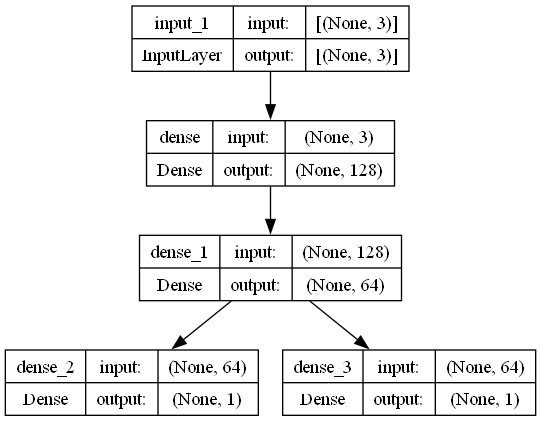

In [12]:
# Visoalize this model

from keras.utils import plot_model

plot_model(model, show_shapes = True)

In [13]:
# See why (3,) is passed as input shape in first in Input layer

import pandas as pd

data = {'Salary': [35000, 30000, 15000, 24000, 20000],
       'Height': [165, 149, 158, 154, 160],
        'Maritial_status': [0, 1, 1, 0, 0]
       }

df = pd.DataFrame(data)

In [14]:
df

,Salary,Height,Maritial_status
0,35000,165,0
1,30000,149,1
2,15000,158,1
3,24000,154,0
4,20000,160,0


In [15]:
df.iloc[0].shape

(3,)

# Model with two input layers and one output

In [16]:
# Define two sets of input

input_a = Input(shape = (32,))
input_b = Input(shape = (128,))

In [17]:
# First branch operats on input_a

x0 = Dense(8, activation = 'relu') (input_a)
x1 = Dense(4, activation = 'relu') (x0)    # Output of branch 1

In [18]:
# Second bracnch operates on second input

y0 = Dense(64, activation = 'relu') (input_b)
y1 = Dense(32, activation = 'relu') (y0)
y2 = Dense(4, activation = 'relu') (y1)    # Output of branch 2

In [19]:
# Concatenating the output of both the branches

combined = concatenate([x1, y2])

In [20]:
# Apply fully connected layers with one output layer

fc0 = Dense(2, activation = 'relu') (combined)
output = Dense(1, activation = 'linear') (fc0)

In [21]:
model2 = Model(inputs = [input_a, input_b], outputs = output)

In [22]:
model2.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_3 (InputLayer)        [(None, 128)]                0         []                            
                                                                                                  
 input_2 (InputLayer)        [(None, 32)]                 0         []                            
                                                                                                  
 dense_6 (Dense)             (None, 64)                   8256      ['input_3[0][0]']             
                                                                                                  
 dense_4 (Dense)             (None, 8)                    264       ['input_2[0][0]']             
                                                                                            

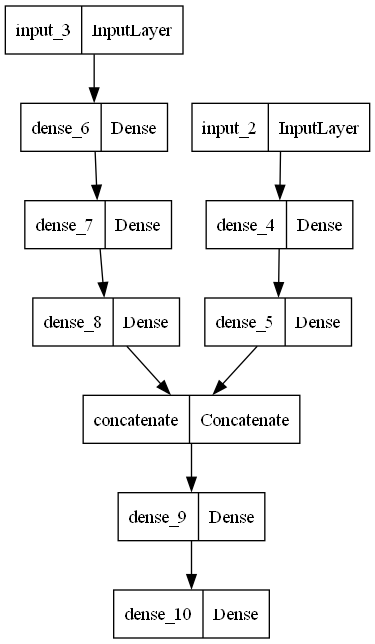

In [23]:
plot_model(model2)

# Now, let's go to google colab. We will predict age and emotion from images of peoples' face.
# Go to colab on nikunjbos26@gmail.com